### Do these 

VML+PPN: BAA TA 24
ctrl slide 2 s2  
exp slide 3 s3

VML: BAA TA 28 
ctrl slide 2 s1
exp slide 3 s1

In [1]:
# Get masks for both segmentaions:

from pathlib import Path

img_paths = list(Path('/scratch/mr2ep/BAA_LAD_all/original_images/').glob('*.tiff'))
lad_paths = list(Path('/scratch/mr2ep/BAA_LAD_all/fiber_masks').glob('*.png'))

lad_names = [f.name for f in lad_paths]

im_path = img_paths[0]

print(im_path)

/scratch/mr2ep/BAA_LAD_all/original_images/BAA02_LGN_exp_prox-slide2_s3.ome.tiff


In [2]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np


Image.MAX_IMAGE_PIXELS = None


def img_to_np(img_file_path):
    img = Image.open(img_file_path)
    img_np = []
    for i in range(3):
        img.seek(i)
        img_np.append(np.array(img))
    img_np = np.array(img_np)
    
    return img_np.transpose((1, 2, 0))

# img_np = img_to_np(img_paths[0])
# plt.imshow(img_np)
# plt.show()

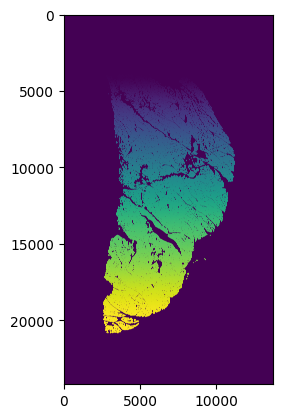

In [3]:
i = 0

img_np = img_to_np(img_paths[i])
img_stem = img_paths[i].stem

lad_path = lad_paths[0].parent / (img_stem + "_cp_masks.png")

lad_mask = np.array(Image.open(lad_path))
plt.imshow(lad_mask)
plt.show()

In [4]:
def img_to_np(img_file_path):
    img = Image.open(img_file_path)
    img_np = []
    for i in range(3):
        img.seek(i)
        img_np.append(np.array(img))
    img_np = np.array(img_np).astype(float)
    img_np = img_np.transpose((1, 2, 0))
    img_np /= np.max(img_np)
    
    return img_np


def randomize_mask_colors(mask_arr):
    colors = np.random.random((3, np.max(mask_arr)+1))
    colors[:, 0] = [0, 0, 0]
    random_masks = colors.T[mask_arr]
    return random_masks




# i_data = img_to_np(img_paths[0])
# mask_opacity = 0.5

# # m_data = np.array(Image.open(mask_path))
# m_colored = randomize_mask_colors(lad_mask)

# # Combine the original image and the mask
# combined_np = np.zeros_like(img_np, dtype=float)
# for c in range(3):  # Combine RGB channels
#     combined_np[..., c] = (mask_opacity * m_colored[..., c]) + ((1 - mask_opacity) * i_data[..., c])

# plt.imshow(combined_np)
# plt.show()


In [20]:
from matplotlib import patches


def plot_img_mask(img, mask, resolution=0.69):
    # correct colors:
    img = img.copy()[:, :, [2, 0, 1]]
    
    # Full image and masks
    mask_rand = randomize_mask_colors(mask)

    # Scale bar variables for full image
    full_scale_bar_length_um = 5000  # 5 mm in microns
    full_scale_bar_height_um = 200    # Height in microns
    full_right_margin = 100         # pixels margin from the right of the image
    full_bottom_margin = 300        # pixels margin from the bottom of the image
    
    # Convert microns to pixels for full image scale bar
    full_scale_bar_length_pixels = full_scale_bar_length_um * resolution
    full_scale_bar_height_pixels = full_scale_bar_height_um * resolution


    make_full_image_scale_bar_rect = lambda : patches.Rectangle(
        (img.shape[1] - full_right_margin - full_scale_bar_length_pixels, 
         img.shape[0] - full_bottom_margin),
        full_scale_bar_length_pixels, full_scale_bar_height_pixels, 
        linewidth=0, edgecolor='none', facecolor='white')


    fig, ax = plt.subplots(1, 1, figsize=(5, 10), tight_layout=True)

    # First row: full images
    ax.imshow(img)
    ax.axis('off')
    # axs[0].set_title('Original Image', fontsize=20)
    scale_bar_full_1 = make_full_image_scale_bar_rect()
    ax.add_patch(scale_bar_full_1)
    
    plt.show()
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 10), tight_layout=True)
    ax.imshow(mask_rand)
    ax.axis('off')
    # axs[1].set_title('Masks', fontsize=20)
    scale_bar_full_1 = make_full_image_scale_bar_rect()
    ax.add_patch(scale_bar_full_1)    
    plt.show()



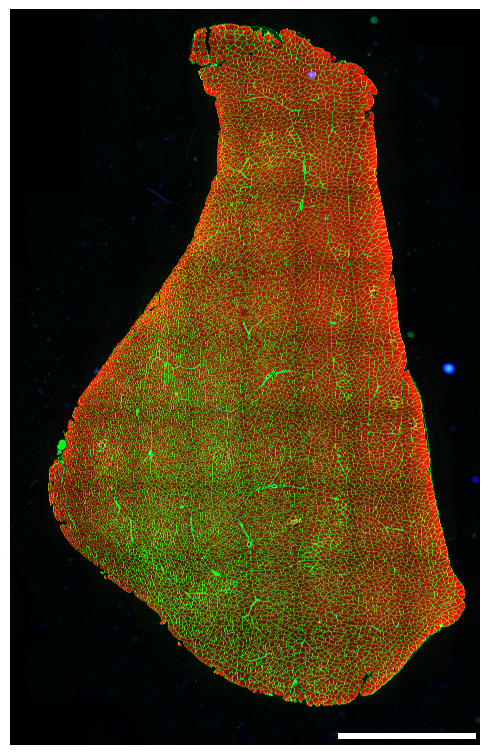

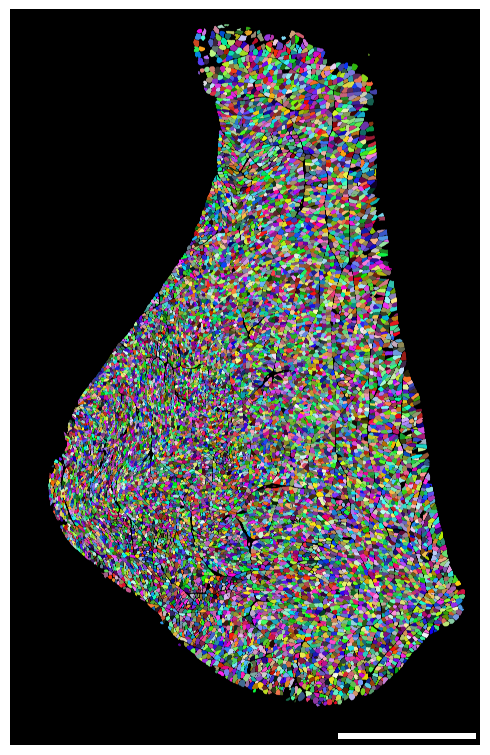

VML + PPN Example


In [21]:
# BAA24_TA_ctrl_prox_slide2_s2	14168		229
img_np = img_to_np('/scratch/mr2ep/BAA_LAD_all/original_images/BAA24_TA_ctrl_prox_slide2_s2.ome.tiff')
lad_mask = np.array(Image.open('/scratch/mr2ep/BAA_LAD_all/fiber_masks/BAA24_TA_ctrl_prox_slide2_s2.ome_cp_masks.png')) 

plot_img_mask(img_np[1000:-3000, 1000:-1000, :], lad_mask[1000:-3000, 1000:-1000])

print("VML + PPN Example")

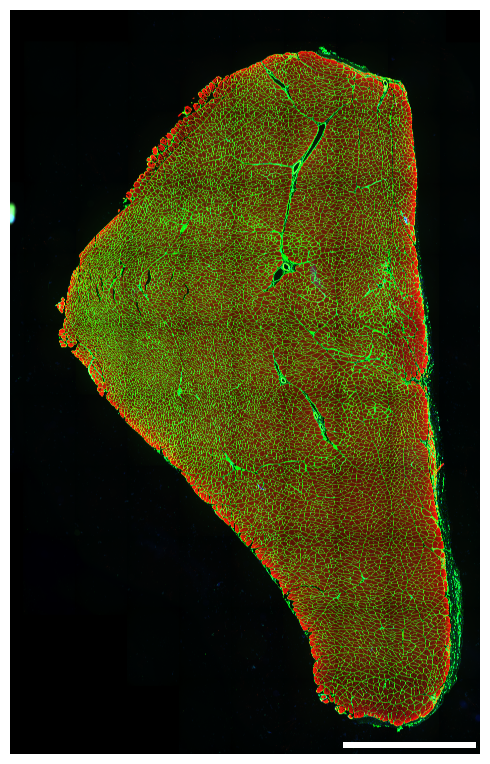

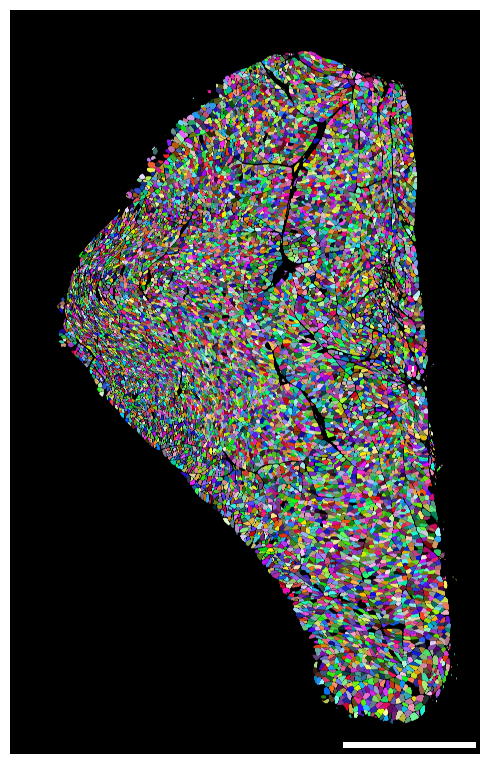

In [22]:
# BAA24_TA_exp_prox_slide3_s3	12544		77
img_np = img_to_np('/scratch/mr2ep/BAA_LAD_all/original_images/BAA24_TA_exp_prox_slide3_s3.ome.tiff')
lad_mask = np.array(Image.open('/scratch/mr2ep/BAA_LAD_all/fiber_masks/BAA24_TA_exp_prox_slide3_s3.ome_cp_masks.png')) 


plot_img_mask(img_np[1000:-2000, 1000:-500, :], lad_mask[1000:-2000, 1000:-500])

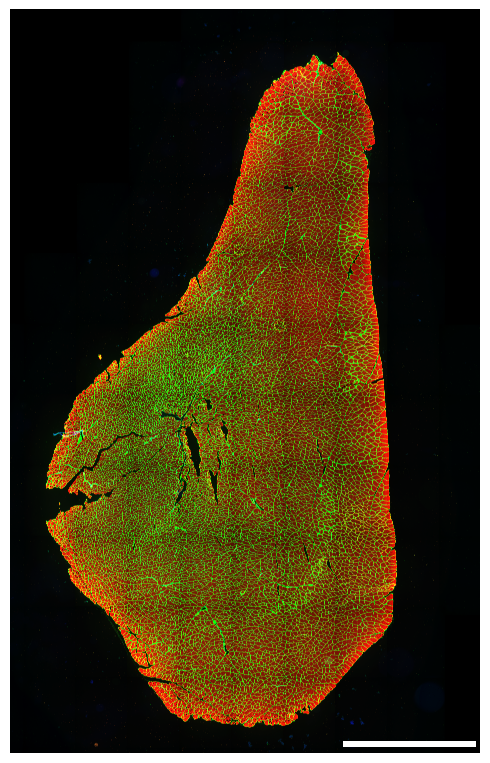

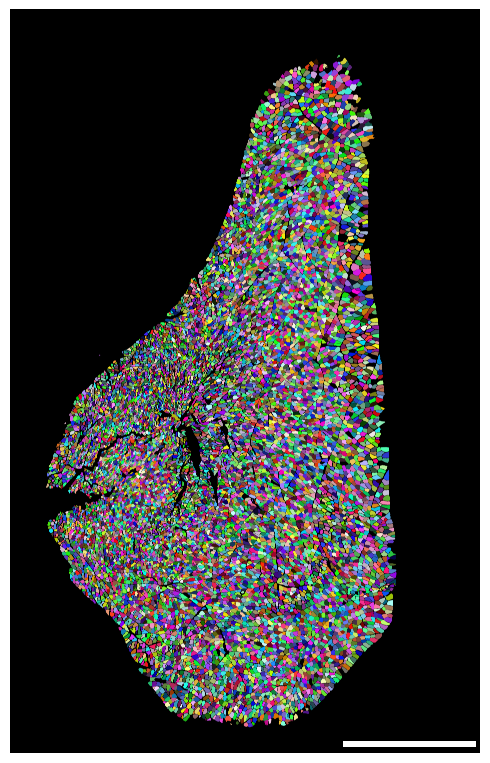

In [23]:
# VML: BAA TA 28 
# ctrl slide 2 s1

img_np = img_to_np('/scratch/mr2ep/BAA_LAD_all/original_images/BAA28_TA_ctrl_prox_slide2_s1.ome.tiff')
lad_mask = np.array(Image.open('/scratch/mr2ep/BAA_LAD_all/fiber_masks/BAA28_TA_ctrl_prox_slide2_s1.ome_cp_masks.png')) 

plot_img_mask(img_np[1000:-2000, 1000:-500, :], lad_mask[1000:-2000, 1000:-500])

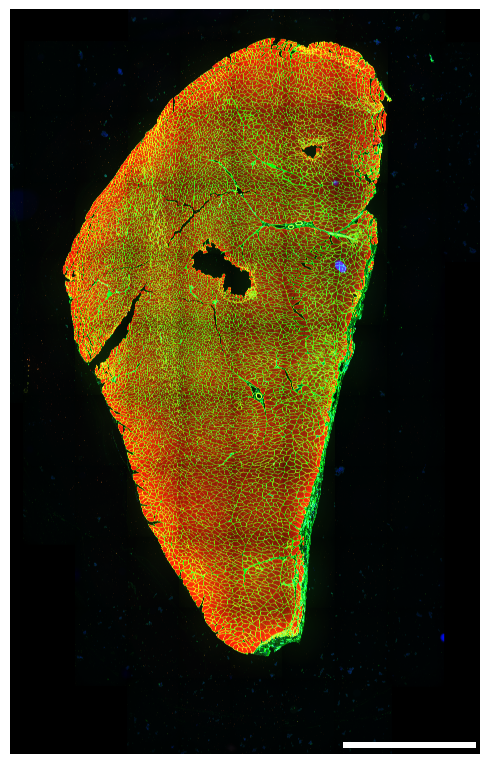

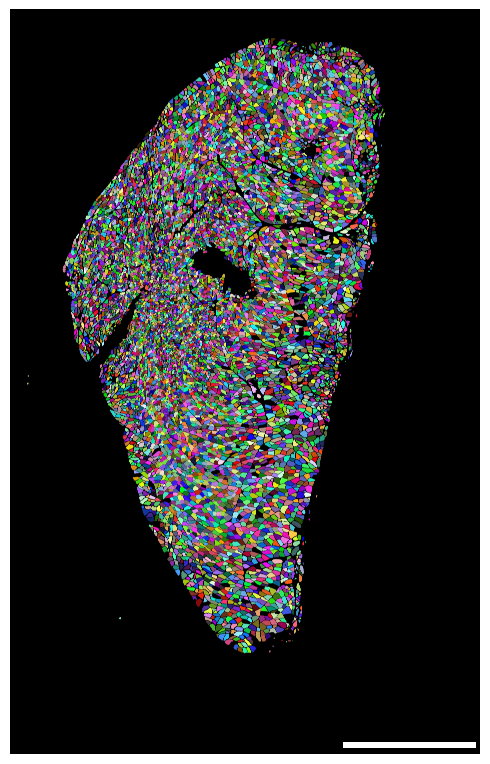

In [24]:
img_np = img_to_np('/scratch/mr2ep/BAA_LAD_all/original_images/BAA28_TA_exp_prox_slide3_s1.ome.tiff')
lad_mask = np.array(Image.open('/scratch/mr2ep/BAA_LAD_all/fiber_masks/BAA28_TA_exp_prox_slide3_s1.ome_cp_masks.png')) 

plot_img_mask(img_np[1000:-2000, 1000:-500, :], lad_mask[1000:-2000, 1000:-500])

# LGN sections

LGN VML + TEMR <br>
BAA03_LGN_ctrl_prox-slide6_s2.ome.tiff<br>
BAA03_LGN_exp_prox-slide4_s2.ome.tiff<br>
<br>
LGN VML + PTN + TEMR<br>
BAA16_LGN_ctrl_prox-slide1_s2.ome.tiff<br>
BAA16_LGN_exp_prox-slide1_s3.ome.tiff<br>




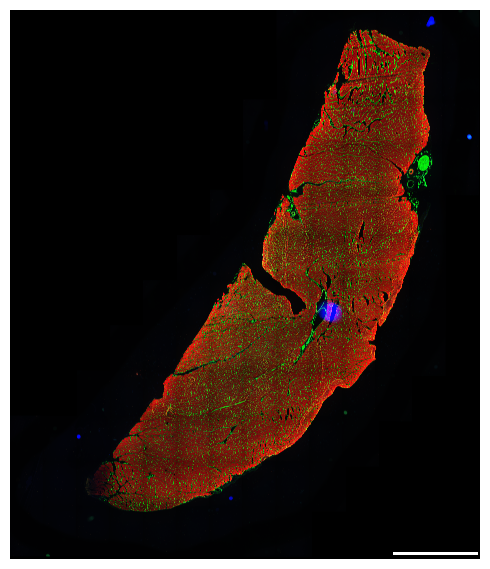

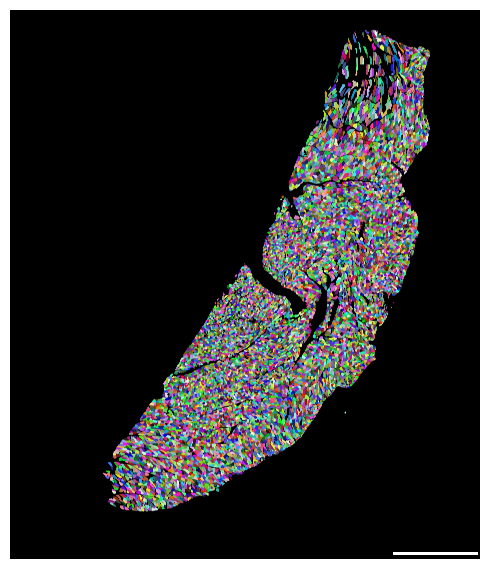

In [25]:
img_np = img_to_np('/scratch/mr2ep/BAA_LAD_all/original_images/BAA03_LGN_ctrl_prox-slide6_s2.ome.tiff')
lad_mask = np.array(Image.open('/scratch/mr2ep/BAA_LAD_all/fiber_masks/BAA03_LGN_ctrl_prox-slide6_s2.ome_cp_masks.png')) 

plot_img_mask(img_np, lad_mask)

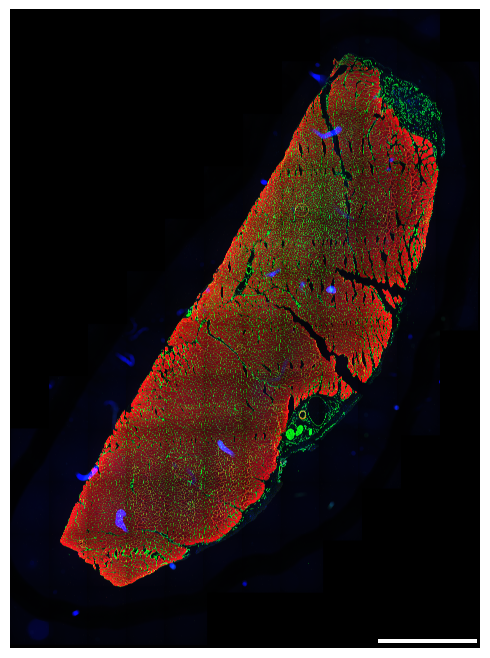

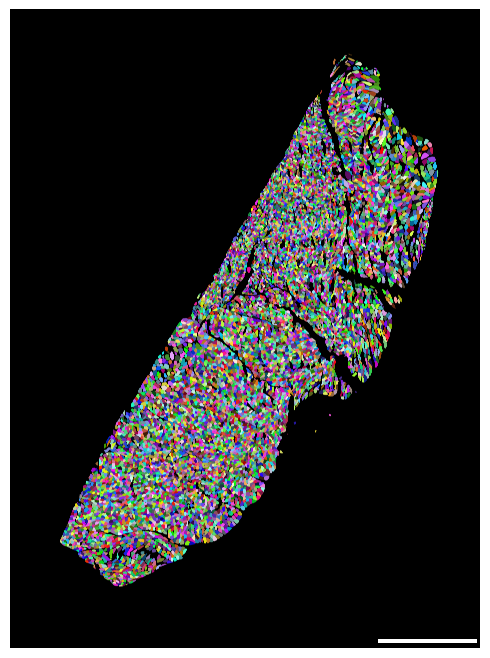

In [26]:
img_np = img_to_np('/scratch/mr2ep/BAA_LAD_all/original_images/BAA03_LGN_exp_prox-slide4_s2.ome.tiff')
lad_mask = np.array(Image.open('/scratch/mr2ep/BAA_LAD_all/fiber_masks/BAA03_LGN_exp_prox-slide4_s2.ome_cp_masks.png')) 

plot_img_mask(img_np, lad_mask)

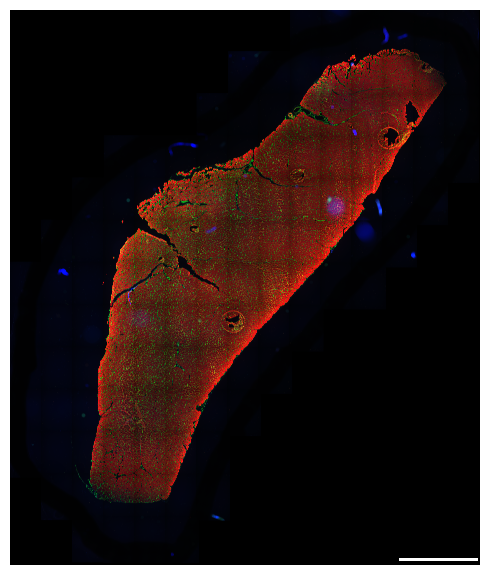

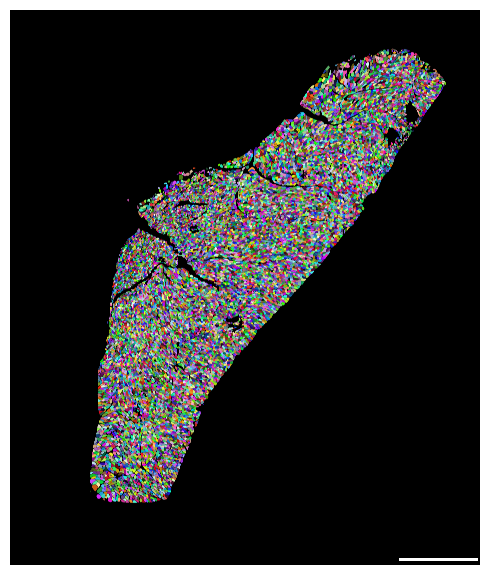

In [27]:
img_np = img_to_np('/scratch/mr2ep/BAA_LAD_all/original_images/BAA16_LGN_ctrl_prox-slide1_s2.ome.tiff')
lad_mask = np.array(Image.open('/scratch/mr2ep/BAA_LAD_all/fiber_masks/BAA16_LGN_ctrl_prox-slide1_s2.ome_cp_masks.png')) 

plot_img_mask(img_np, lad_mask)

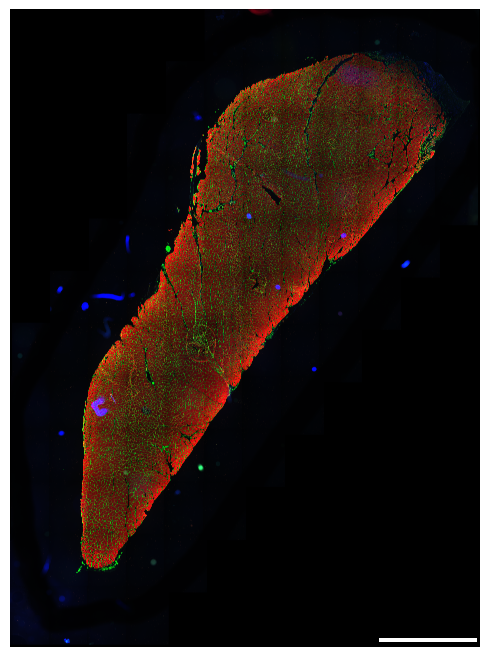

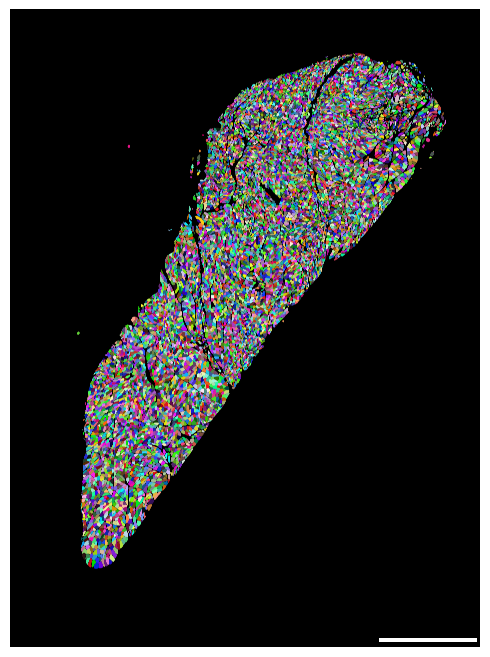

In [28]:
img_np = img_to_np('/scratch/mr2ep/BAA_LAD_all/original_images/BAA16_LGN_exp_prox-slide1_s3.ome.tiff')
lad_mask = np.array(Image.open('/scratch/mr2ep/BAA_LAD_all/fiber_masks/BAA16_LGN_exp_prox-slide1_s3.ome_cp_masks.png')) 

plot_img_mask(img_np, lad_mask)